# Distribución de la Ganancia: variabilidad por datos y por modelo

Hasta ahora medimos la ganancia de un árbol como si fuera un número fijo. Pero ese número depende de:

* **qué filas** terminaron en train/test (el split es aleatorio),
* **qué mes** se usa para entrenar y para testear,
* **qué modelo** (hiperparámetros) se entrena.

El objetivo de esta notebook es construir una forma de **graficar la distribución de la ganancia** ante estas fuentes de variación, en lugar de mirar un único valor puntual que puede ser optimista o pesimista por azar.

Esta notebook arranca solo con la carga del dataset a memoria. Una vez confirmado que los datos están bien cargados, definimos juntos el experimento (qué se compara, cuántas repeticiones, qué semillas, etc.) antes de escribir la simulación y los gráficos.

## Setup

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedShuffleSplit

Variables importantes

In [2]:
dataset_path = '../data/'
dataset_file = 'competencia_01.csv'

ganancia_acierto = 1_072_500
costo_estimulo = 27_500

semillas = [852583, 771227, 676057, 482687, 399221]  # semillas propias (ver competencia/src/config.py)

## Carga del dataset

A diferencia de `z201_Sobre_Árboles`, acá **no** filtramos a un único `foto_mes` al cargar: necesitamos tener varios períodos disponibles en memoria para poder comparar, por ejemplo, entrenar en un mes y testear en otro.

In [3]:
data = pd.read_csv(dataset_path + dataset_file)
data.shape

(983061, 155)

Chequeo rápido: cuántos registros hay por período y si la clase está definida en cada uno.

In [4]:
data.groupby('foto_mes').agg(
    registros=('numero_de_cliente', 'size'),
    con_clase=('clase_ternaria', lambda s: s.notna().sum())
)

In [5]:
data.head()

## Definición del experimento

Pensemos un modelo como una función que depende de tres cosas: el set de datos de entrenamiento $X$, las clases $J$ (`clase_ternaria`) y los hiperparámetros $h$. Entrenar es fijar $h$ y ajustar la función a un $X$ particular; la ganancia que obtenemos es solo **una muestra** de lo que ese modelo puede dar, porque si hubiéramos entrenado con otro subconjunto de datos $X'$ (misma población, otra muestra) la ganancia habría sido distinta.

**Plan:**

1. Fijamos `mes_train = 202103` (de donde salen los distintos $X'$) y `mes_test = 202105` (fijo, out-of-time — nunca se remuestrea, así medimos siempre sobre el mismo objetivo).
2. Para un modelo dado (hiperparámetros $h$ fijos), generamos muchos $X'$ remuestreando `mes_train` (`StratifiedShuffleSplit`, conserva la proporción de clases), entrenamos un árbol con cada $X'$, y medimos su ganancia siempre sobre el mismo `mes_test`. Eso nos da una **distribución de ganancias** para ese modelo.
3. Repetimos el punto 2 con otro conjunto de hiperparámetros $h'$ (otro modelo), obteniendo otra distribución.
4. Graficamos ambas distribuciones superpuestas para comparar: no solo qué modelo gana en promedio, sino cuál es más estable (menor varianza).

In [6]:
mes_train = 202103
mes_test = 202105

X_train = data[data['foto_mes'] == mes_train].drop(columns=['clase_ternaria'])
y_train = data[data['foto_mes'] == mes_train]['clase_ternaria']

X_test = data[data['foto_mes'] == mes_test].drop(columns=['clase_ternaria'])
y_test = data[data['foto_mes'] == mes_test]['clase_ternaria']

X_train.shape, X_test.shape

((162900, 154), (163768, 154))

### Función de ganancia

Igual que en `z201_Sobre_Árboles`: para cada cliente, si la probabilidad predicha de `BAJA+2` supera el `threshold`, se le envía el estímulo. Si acierta (era `BAJA+2`) suma `ganancia_acierto`, si no, resta `costo_estimulo`.

In [7]:
def ganancia(model, X, y, prop=1, threshold=0.025):

    class_index = np.where(model.classes_ == "BAJA+2")[0][0]
    y_hat = model.predict_proba(X)

    @np.vectorize
    def ganancia_row(predicted, actual, threshold=threshold):
        return (predicted >= threshold) * (ganancia_acierto if actual == "BAJA+2" else -costo_estimulo)

    return ganancia_row(y_hat[:, class_index], y).sum() / prop

### Distribución de ganancia para un modelo dado

`distribucion_ganancia` recibe los hiperparámetros del árbol ($h$) y devuelve una lista de `n_splits` valores de ganancia: en cada repetición se remuestrea `X_train` (quedándonos con el `train_size` de cada split, vía `StratifiedShuffleSplit`), se entrena un árbol nuevo con esos datos, y se lo evalúa **siempre** contra el `X_test`/`y_test` fijo de `mes_test`.

Así aislamos el efecto de la variabilidad de los datos de entrenamiento sobre la ganancia real out-of-time, sin filtrar señal evaluando contra el propio mes de entrenamiento.

In [8]:
def distribucion_ganancia(tree_params, X_train, y_train, X_test, y_test,
                           n_splits=30, test_size=0.3, random_state=17, threshold=0.025):

    sss = StratifiedShuffleSplit(n_splits=n_splits, test_size=test_size, random_state=random_state)

    ganancias = []
    for train_index, _ in sss.split(X_train, y_train):
        model = DecisionTreeClassifier(**tree_params)
        model.fit(X_train.iloc[train_index], y_train.iloc[train_index])
        ganancias.append(ganancia(model, X_test, y_test, threshold=threshold))

    return ganancias

## Corremos el experimento para dos modelos

Comparamos dos árboles que solo difieren en `max_depth` (uno más simple, uno más complejo) para ver si la profundidad extra se traduce en más ganancia, o solo en más varianza.

In [9]:
modelos = {
    'max_depth=5':  {'criterion': 'gini', 'max_depth': 5,  'min_samples_split': 80},
    'max_depth=10': {'criterion': 'gini', 'max_depth': 10, 'min_samples_split': 80},
}

n_splits = 30

resultados = []
for nombre, params in modelos.items():
    ganancias = distribucion_ganancia(
        params, X_train, y_train, X_test, y_test,
        n_splits=n_splits, random_state=semillas[0]
    )
    resultados.extend({'Ganancia': g, 'Modelo': nombre} for g in ganancias)

df_ganancias = pd.DataFrame(resultados)
df_ganancias.groupby('Modelo')['Ganancia'].describe()

### Comparando las distribuciones

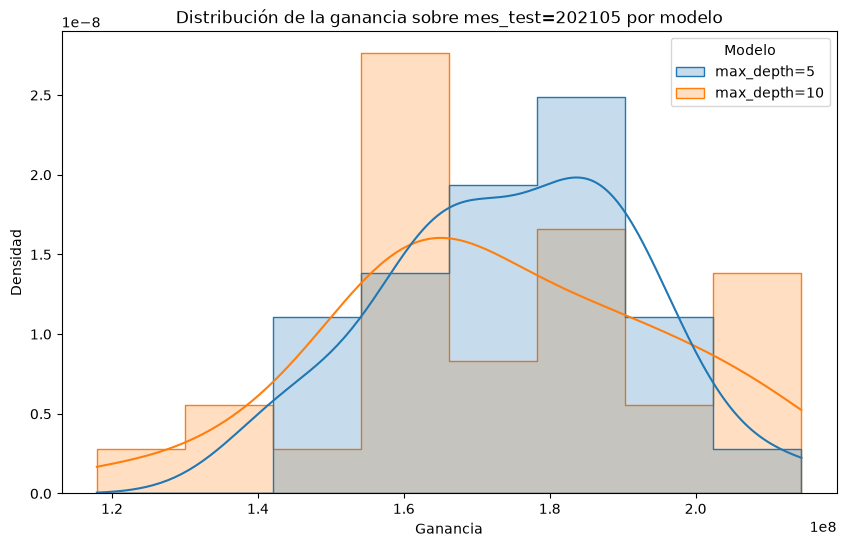

In [10]:
plt.figure(figsize=(10, 6))
sns.histplot(data=df_ganancias, x='Ganancia', hue='Modelo', kde=True,
             stat='density', common_norm=False, element='step')
plt.title(f'Distribución de la ganancia sobre mes_test={mes_test} por modelo')
plt.xlabel('Ganancia')
plt.ylabel('Densidad')
plt.show()

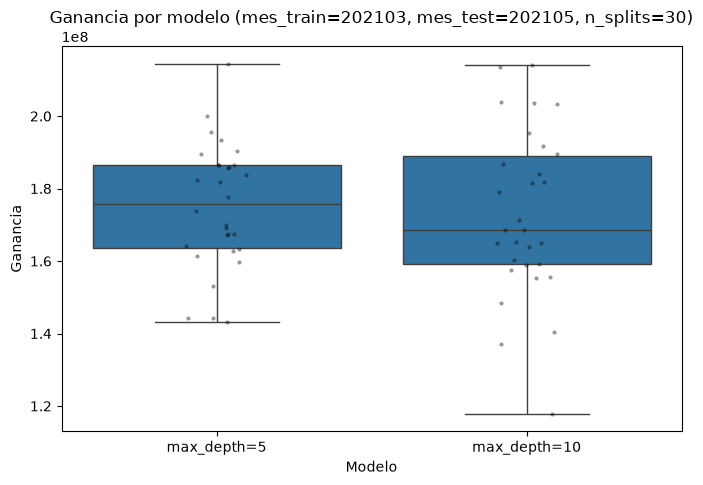

In [11]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_ganancias, x='Modelo', y='Ganancia')
sns.stripplot(data=df_ganancias, x='Modelo', y='Ganancia', color='black', alpha=0.4, size=3)
plt.title(f'Ganancia por modelo (mes_train={mes_train}, mes_test={mes_test}, n_splits={n_splits})')
plt.show()

# Ahora comparo con marzo, mismo mes de train que de test

In [12]:
mes_train = 202103
mes_test = 202103

X_train = data[data['foto_mes'] == mes_train].drop(columns=['clase_ternaria'])
y_train = data[data['foto_mes'] == mes_train]['clase_ternaria']

X_test = data[data['foto_mes'] == mes_test].drop(columns=['clase_ternaria'])
y_test = data[data['foto_mes'] == mes_test]['clase_ternaria']

X_train.shape, X_test.shape

((162900, 154), (162900, 154))

In [13]:
modelos = {
    'max_depth=5':  {'criterion': 'gini', 'max_depth': 5,  'min_samples_split': 80},
    'max_depth=10': {'criterion': 'gini', 'max_depth': 10, 'min_samples_split': 80},
}

n_splits = 30

resultados = []
for nombre, params in modelos.items():
    ganancias = distribucion_ganancia(
        params, X_train, y_train, X_test, y_test,
        n_splits=n_splits, random_state=semillas[0]
    )
    resultados.extend({'Ganancia': g, 'Modelo': nombre} for g in ganancias)

df_ganancias = pd.DataFrame(resultados)
df_ganancias.groupby('Modelo')['Ganancia'].describe()

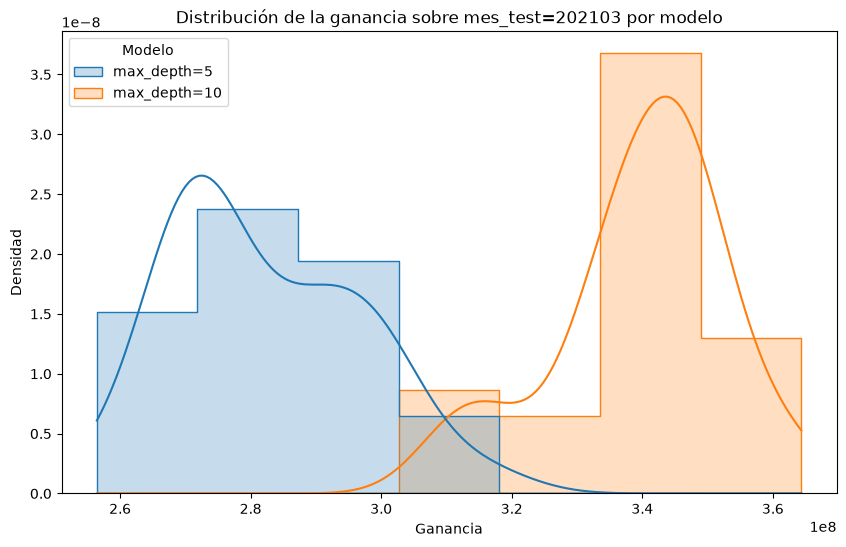

In [14]:
plt.figure(figsize=(10, 6))
sns.histplot(data=df_ganancias, x='Ganancia', hue='Modelo', kde=True,
             stat='density', common_norm=False, element='step')
plt.title(f'Distribución de la ganancia sobre mes_test={mes_test} por modelo')
plt.xlabel('Ganancia')
plt.ylabel('Densidad')
plt.show()

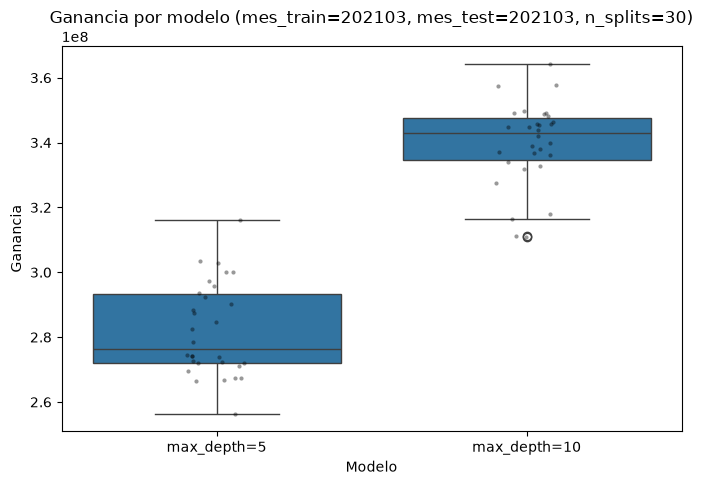

In [15]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_ganancias, x='Modelo', y='Ganancia')
sns.stripplot(data=df_ganancias, x='Modelo', y='Ganancia', color='black', alpha=0.4, size=3)
plt.title(f'Ganancia por modelo (mes_train={mes_train}, mes_test={mes_test}, n_splits={n_splits})')
plt.show()

In [16]:
mes_train = 202103
mes_test = 202104

X_train = data[data['foto_mes'] == mes_train].drop(columns=['clase_ternaria'])
y_train = data[data['foto_mes'] == mes_train]['clase_ternaria']

X_test = data[data['foto_mes'] == mes_test].drop(columns=['clase_ternaria'])
y_test = data[data['foto_mes'] == mes_test]['clase_ternaria']

X_train.shape, X_test.shape

((162900, 154), (163284, 154))

In [17]:
modelos = {
    'max_depth=5':  {'criterion': 'gini', 'max_depth': 5,  'min_samples_split': 80},
    'max_depth=10': {'criterion': 'gini', 'max_depth': 10, 'min_samples_split': 80},
}

n_splits = 30

resultados = []
for nombre, params in modelos.items():
    ganancias = distribucion_ganancia(
        params, X_train, y_train, X_test, y_test,
        n_splits=n_splits, random_state=semillas[0]
    )
    resultados.extend({'Ganancia': g, 'Modelo': nombre} for g in ganancias)

df_ganancias = pd.DataFrame(resultados)
df_ganancias.groupby('Modelo')['Ganancia'].describe()

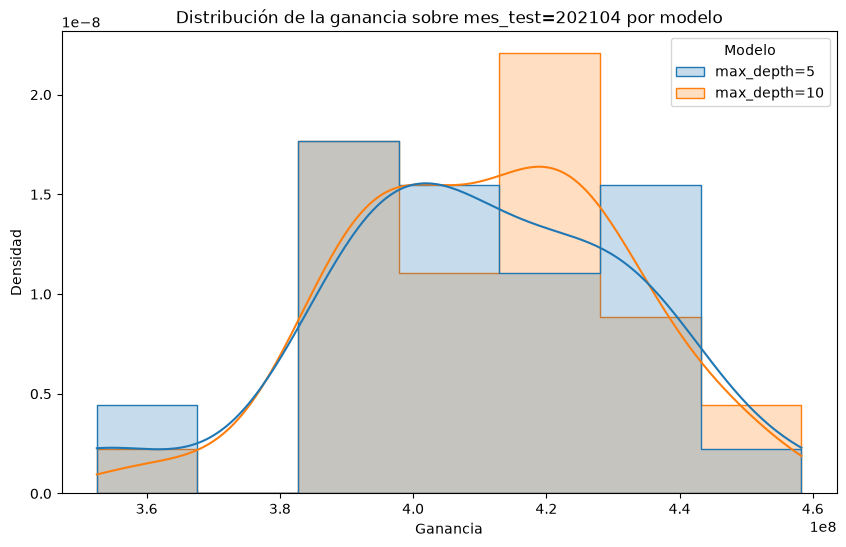

In [18]:
plt.figure(figsize=(10, 6))
sns.histplot(data=df_ganancias, x='Ganancia', hue='Modelo', kde=True,
             stat='density', common_norm=False, element='step')
plt.title(f'Distribución de la ganancia sobre mes_test={mes_test} por modelo')
plt.xlabel('Ganancia')
plt.ylabel('Densidad')
plt.show()

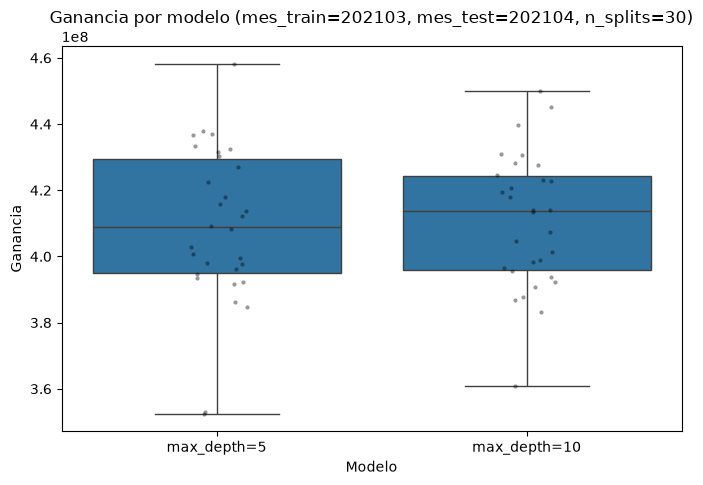

In [19]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_ganancias, x='Modelo', y='Ganancia')
sns.stripplot(data=df_ganancias, x='Modelo', y='Ganancia', color='black', alpha=0.4, size=3)
plt.title(f'Ganancia por modelo (mes_train={mes_train}, mes_test={mes_test}, n_splits={n_splits})')
plt.show()

## Para pensar / tarea

* ¿Qué modelo tiene mayor ganancia **media**? ¿Cuál tiene **menor varianza** (más estable)?
* Si tuviera que elegir uno para producción, ¿priorizaría la media o la estabilidad? ¿Por qué no son lo mismo?
* Las distribuciones, ¿se solapan mucho? Si se solapan bastante, ¿alcanzan estas repeticiones para decir con confianza que un modelo es mejor que el otro?
* Agregue un tercer (o cuarto) modelo variando otros hiperparámetros (`criterion`, `min_samples_leaf`, `min_samples_split`) y compare las distribuciones.
* Pruebe aumentar `n_splits`. ¿Cambia la forma de la distribución o solo se vuelve más "suave"?

## Optimización de hiperparámetros con Optuna

Hasta acá elegimos $h$ (los hiperparámetros del árbol) a mano y comparamos un puñado de opciones. [Optuna](https://optuna.org/) hace búsqueda bayesiana (por defecto, TPE): en vez de probar una grilla fija o combinaciones al azar, usa los resultados de los *trials* anteriores para decidir qué configuración probar a continuación, así converge más rápido a un buen $h$.

Detalles importantes de cómo lo conectamos con lo que ya construimos:

* La **métrica a maximizar** en cada *trial* es la **media** de `distribucion_ganancia(h, ...)` — no un único valor de ganancia, para no optimizar hacia un remuestreo particular que haya sido optimista por azar.
* Dentro de la búsqueda usamos un `n_splits` chico (para que cada *trial* sea rápido) pero con el **mismo `random_state`** en todos los trials: así todas las configuraciones se comparan sobre exactamente los mismos remuestreos de `X_train`, y la diferencia entre trials se debe solo a $h$, no a qué folds les tocó.
* Una vez encontrado el mejor $h$, recién ahí calculamos su distribución completa (con más `n_splits`) para compararlo, en igualdad de condiciones, contra los modelos manuales de arriba.

In [20]:
%%bash
pip install -q optuna


[notice] A new release of pip is available: 2

6.1.2 -> 26.2.1
[notice] To up

date, run: pip install --upgrade pip


In [21]:
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

### Función objetivo y espacio de búsqueda

In [22]:
def objective(trial):
    tree_params = {
        'criterion': trial.suggest_categorical('criterion', ['gini', 'entropy']),
        'max_depth': trial.suggest_int('max_depth', 3, 15),
        'min_samples_split': trial.suggest_int('min_samples_split', 20, 800),
        'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 200),
    }

    ganancias_trial = distribucion_ganancia(
        tree_params, X_train, y_train, X_test, y_test,
        n_splits=5, random_state=semillas[0]
    )
    return np.mean(ganancias_trial)

In [23]:
study = optuna.create_study(
    direction='maximize',
    sampler=optuna.samplers.TPESampler(seed=semillas[0])
)
study.optimize(objective, n_trials=40, show_progress_bar=True)

print('Mejores hiperparámetros:', study.best_params)
print('Ganancia media (n_splits=5):', study.best_value)

  0%|          | 0/40 [00:00<?, ?it/s]

Mejores hiperparámetros: {'criterion': 'entropy', 'max_depth': 6, 'min_samples_split': 309, 'min_samples_leaf': 188}
Ganancia media (n_splits=5): 436474500.0


### Distribución del modelo optimizado vs. los modelos manuales

Con `study.best_params` corremos `distribucion_ganancia` con el mismo `n_splits` que usamos para `max_depth=5` y `max_depth=10`, y lo sumamos a `df_ganancias` para comparar las tres distribuciones en el mismo gráfico.

In [24]:
ganancias_optuna = distribucion_ganancia(
    study.best_params, X_train, y_train, X_test, y_test,
    n_splits=n_splits, random_state=semillas[0]
)

df_ganancias = pd.concat([
    df_ganancias,
    pd.DataFrame({'Ganancia': ganancias_optuna, 'Modelo': 'optuna'})
], ignore_index=True)

df_ganancias.groupby('Modelo')['Ganancia'].describe()

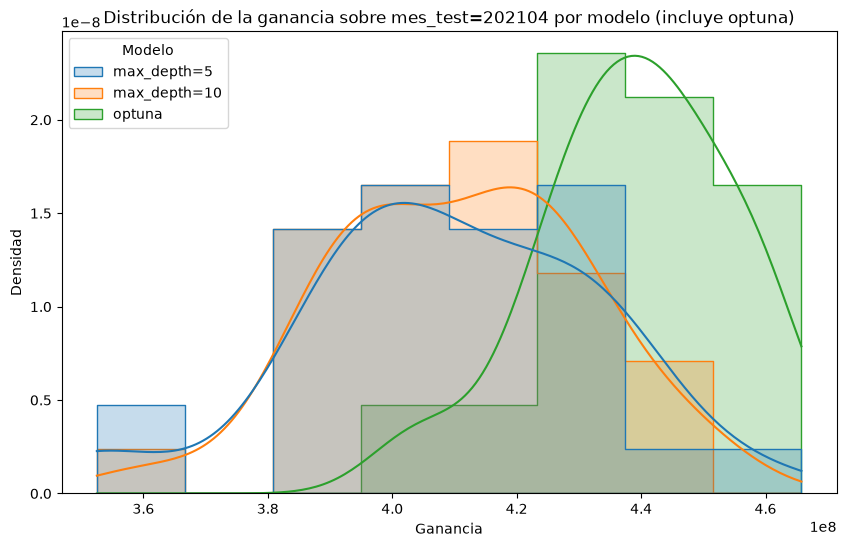

In [25]:
plt.figure(figsize=(10, 6))
sns.histplot(data=df_ganancias, x='Ganancia', hue='Modelo', kde=True,
             stat='density', common_norm=False, element='step')
plt.title(f'Distribución de la ganancia sobre mes_test={mes_test} por modelo (incluye optuna)')
plt.xlabel('Ganancia')
plt.ylabel('Densidad')
plt.show()

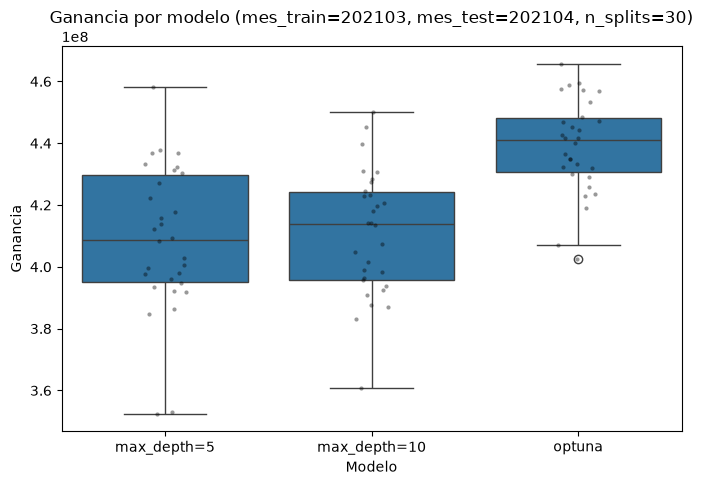

In [26]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_ganancias, x='Modelo', y='Ganancia')
sns.stripplot(data=df_ganancias, x='Modelo', y='Ganancia', color='black', alpha=0.4, size=3)
plt.title(f'Ganancia por modelo (mes_train={mes_train}, mes_test={mes_test}, n_splits={n_splits})')
plt.show()

/var/folders/1b/j3xxc19j57nc1s4qmbxn35dh0000gn/T/ipykernel_38941/2537861117.py:3: ExperimentalWarning: optuna.visualization.matplotlib._contour.plot_contour is experimental (supported from v2.2.0). The interface can change in the future.
  plot_contour(study, params=['max_depth', 'min_samples_split'], target_name='Ganancia')


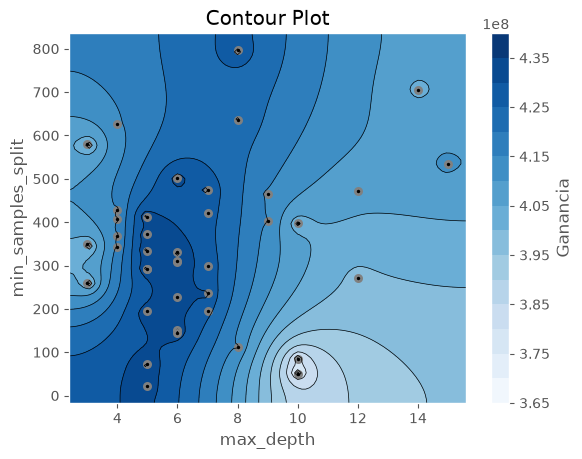

In [45]:
from optuna.visualization.matplotlib import plot_contour

plot_contour(study, params=['max_depth', 'min_samples_split'], target_name='Ganancia')
plt.show()

### Para pensar / tarea (Optuna)

* El óptimo, ¿le ganó a `max_depth=5` y `max_depth=10` en media? ¿En varianza?
* `study.optimize` reutiliza el mismo `random_state` en todos los trials — ¿qué riesgo tiene esto? (pista: el $h$ elegido podría estar sobreajustado a *ese* conjunto particular de remuestreos, no a la variabilidad real de los datos).
* Pruebe correr `distribucion_ganancia` para `study.best_params` con **otro** `random_state` (folds distintos a los usados durante la búsqueda) y compare: si la ganancia media cae mucho, es señal de que el paso anterior optimizó "de más" para esos folds específicos.
* Optuna trae utilidades de visualización propias (requieren `plotly`): `optuna.visualization.plot_optimization_history(study)` y `optuna.visualization.plot_param_importances(study)` — útiles para ver qué hiperparámetro pesó más en el resultado.